In [1]:
import pandas as pd

In [2]:
menu_df = pd.DataFrame(
    {
        'Item': ['Apple', 'Granola', 'Salad'],
        'Price': [3, 5, 5]
    }
)

In [3]:
menu_df

,Item,Price
0,Apple,3
1,Granola,5
2,Salad,5


In [4]:
population = pd.read_csv('atlantis.csv')

In [5]:
population.tail(3)

,year,population
19,2019,32500
20,2020,33200
21,2021,33800


In [6]:
population.shape

(22, 2)

In [7]:
population.columns

Index(['year', 'population'], dtype='object')

In [8]:
population.dtypes

year          int64
population    int64
dtype: object

In [9]:
population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        22 non-null     int64
 1   population  22 non-null     int64
dtypes: int64(2)
memory usage: 484.0 bytes


In [10]:
population.describe()

,year,population
count,22.000000,22.000000
mean,2010.500000,22418.181818
std,6.493587,7100.411548
min,2000.000000,12400.000000
25%,2005.250000,16100.000000
50%,2010.500000,21800.000000
75%,2015.750000,27750.000000
max,2021.000000,33800.000000


In [11]:
population.isna().sum()

year          0
population    0
dtype: int64

In [19]:
population[population['year'] >= 2020]

,year,population
20,2020,33200
21,2021,33800


In [26]:
population.iloc[-5:, 1]

17    29600
18    32100
19    32500
20    33200
21    33800
Name: population, dtype: int64

In [31]:
population.loc[population['year'] >= 2020, ['year', 'population']]

,year,population
20,2020,33200
21,2021,33800


In [37]:
population.loc[(population['year'] >= 2017) | (population['year'] <= 2020)]

,year,population
0,2000,12400
1,2001,12800
2,2002,13800
3,2003,13600
4,2004,14200
5,2005,15600
6,2006,17600
7,2007,19200
8,2008,20300
9,2009,20800


In [38]:
population['pop_thousands'] = population['population'] / 1000

In [39]:
population.head()

,year,population,pop_thousands
0,2000,12400,12.4
1,2001,12800,12.8
2,2002,13800,13.8
3,2003,13600,13.6
4,2004,14200,14.2


In [40]:
population['diff'] = population['population'].diff()
population.head()

,year,population,pop_thousands,diff
0,2000,12400,12.4,NaN
1,2001,12800,12.8,400.0
2,2002,13800,13.8,1000.0
3,2003,13600,13.6,-200.0
4,2004,14200,14.2,600.0


In [45]:
population['pct_diff'] = population['population'].pct_change() * 100
population.head(6)

,year,population,pop_thousands,diff,pct_diff
0,2000,12400,12.4,NaN,NaN
1,2001,12800,12.8,400.0,3.225806
2,2002,13800,13.8,1000.0,7.812500
3,2003,13600,13.6,-200.0,-1.449275
4,2004,14200,14.2,600.0,4.411765
5,2005,15600,15.6,1400.0,9.859155


In [44]:
population['pct_diff'].idxmax()

6

In [46]:
population.iloc[6, :]

year              2006.000000
population       17600.000000
pop_thousands       17.600000
diff              2000.000000
pct_diff            12.820513
Name: 6, dtype: float64

In [49]:
population.loc[population['pct_diff'] > population['pct_diff'].mean()]

,year,population,pop_thousands,diff,pct_diff
2,2002,13800,13.8,1000.0,7.812500
5,2005,15600,15.6,1400.0,9.859155
6,2006,17600,17.6,2000.0,12.820513
7,2007,19200,19.2,1600.0,9.090909
8,2008,20300,20.3,1100.0,5.729167
11,2011,22400,22.4,1200.0,5.660377
14,2014,25800,25.8,1300.0,5.306122
16,2016,28300,28.3,2200.0,8.429119
18,2018,32100,32.1,2500.0,8.445946


<Axes: >

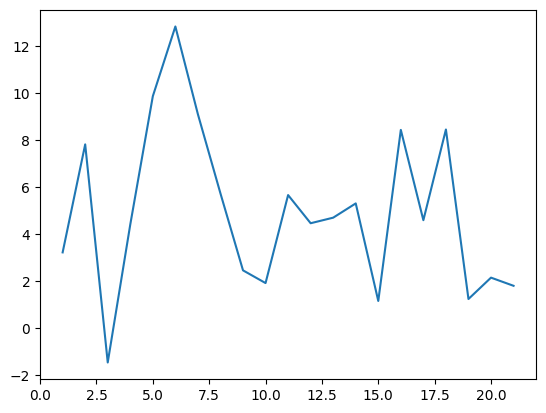

In [51]:
population['pct_diff'].plot.line()

<Axes: ylabel='Frequency'>

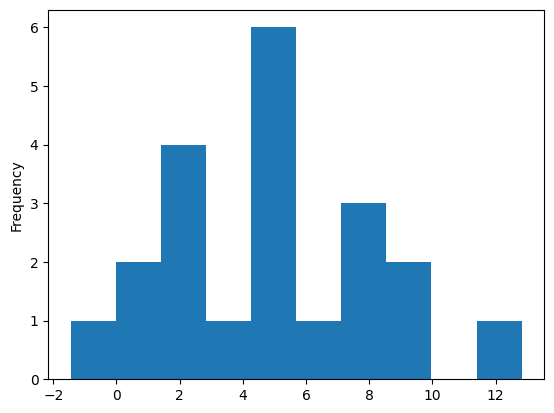

In [52]:
population['pct_diff'].plot.hist()

<Axes: xlabel='diff', ylabel='pct_diff'>

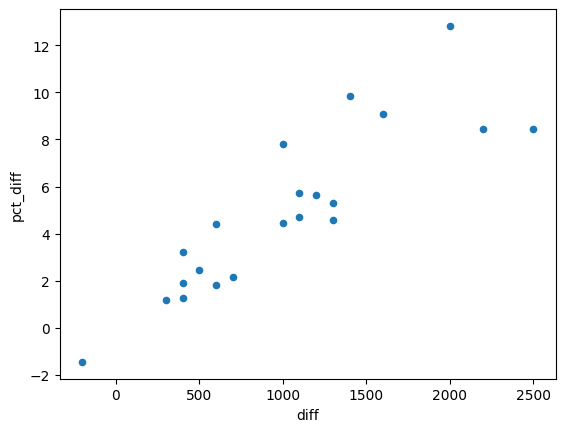

In [55]:
population.plot.scatter(x='diff', y='pct_diff')